In [1]:
import os

def build_dataset(root_path, subjects):
    data_list = []

    for subject in subjects:
        ct_path = os.path.join(root_path, subject, "CT")
        uct_path = os.path.join(root_path, subject, "UCT")

        ct_file = None
        mask_file = None

        # find files
        for f in os.listdir(ct_path):
            if "CT_RAW" in f:
                ct_file = os.path.join(ct_path, f)

        for f in os.listdir(uct_path):
            if f.endswith("_LABELS.nii"):
                mask_file = os.path.join(uct_path, f)

        if ct_file and mask_file:
            data_list.append({
                "subject": subject,
                "ct": ct_file,
                "mask": mask_file
            })

    return data_list

In [2]:
train_subjects = [f"F{i:02d}" for i in range(1, 11)] + [f"T{i:02d}" for i in range(1, 6)]

val_subjects = [f"F{i:02d}" for i in range(11, 14)]

test_subjects = [f"F{i:02d}" for i in range(14, 16)] + [f"T{i:02d}" for i in range(6, 9)]

In [3]:
root = "DATASET_ROOT"

train_data = build_dataset(root, train_subjects)
val_data = build_dataset(root, val_subjects)
test_data = build_dataset(root, test_subjects)

print("Train:", len(train_data))
print("Val:", len(val_data))
print("Test:", len(test_data))

Train: 15
Val: 3
Test: 5


In [5]:
print(test_data[:23])

[{'subject': 'F14', 'ct': 'DATASET_ROOT\\F14\\CT\\F14_CT_RAW.nii', 'mask': 'DATASET_ROOT\\F14\\UCT\\F14_uCT_LABELS.nii'}, {'subject': 'F15', 'ct': 'DATASET_ROOT\\F15\\CT\\F15_CT_RAW.nii', 'mask': 'DATASET_ROOT\\F15\\UCT\\F15_uCT_LABELS.nii'}, {'subject': 'T06', 'ct': 'DATASET_ROOT\\T06\\CT\\T06_CT_RAW.nii', 'mask': 'DATASET_ROOT\\T06\\UCT\\T06_uCT_LABELS.nii'}, {'subject': 'T07', 'ct': 'DATASET_ROOT\\T07\\CT\\T07_CT_RAW.nii', 'mask': 'DATASET_ROOT\\T07\\UCT\\T07_uCT_LABELS.nii'}, {'subject': 'T08', 'ct': 'DATASET_ROOT\\T08\\CT\\T08_CT_RAW.nii', 'mask': 'DATASET_ROOT\\T08\\UCT\\T08_uCT_LABELS.nii'}]


In [18]:
img = nib.load(sample["ct"])

print("shape:", img.shape)
print("spacing:", img.header.get_zooms())

shape: (115, 118, 100)
spacing: (0.15625, 0.15625, 0.19999999)


In [19]:
shape = np.array(img.shape)
spacing = np.array(img.header.get_zooms())

physical_size_mm = shape * spacing

print(physical_size_mm)

[17.96875    18.4375     19.99999881]


In [20]:
import nibabel as nib
import numpy as np

sample = train_data[3]
ct = nib.load(sample["ct"])
mask = nib.load(sample["mask"])

print("Subject:", sample["subject"])
print("CT shape:", ct.shape)
print("Mask shape:", mask.shape)
print("Affine close:", np.allclose(ct.affine, mask.affine))

Subject: F04
CT shape: (113, 109, 84)
Mask shape: (252, 268, 255)
Affine close: False


In [21]:
# import SimpleITK as sitk
# import numpy as np
# import nibabel as nib

# def resample_mask_to_ct(ct_path, mask_path):
#     ct = sitk.ReadImage(ct_path)
#     mask = sitk.ReadImage(mask_path)

#     resampler = sitk.ResampleImageFilter()
#     resampler.SetReferenceImage(ct)
#     resampler.SetInterpolator(sitk.sitkNearestNeighbor) 

#     mask_resampled = resampler.Execute(mask)

#     return ct, mask_resampled


# sample = train_data[0]

# ct_img, mask_img = resample_mask_to_ct(sample["ct"], sample["mask"])

# ct_arr = sitk.GetArrayFromImage(ct_img)
# mask_arr = sitk.GetArrayFromImage(mask_img)

# print("CT:", ct_arr.shape)
# print("Mask:", mask_arr.shape)

CT: (97, 115, 95)
Mask: (97, 115, 95)


In [42]:
print("CT spacing:", ct_img.GetSpacing())
print("CT origin:", ct_img.GetOrigin())
print("CT direction:", ct_img.GetDirection())

print("Mask spacing:", mask_img.GetSpacing())
print("Mask origin:", mask_img.GetOrigin())
print("Mask direction:", mask_img.GetDirection())

CT spacing: (0.15625, 0.15625, 0.20000001788139343)
CT origin: (9.328149795532227, 95.51570129394531, -85.4000015258789)
CT direction: (-1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)
Mask spacing: (0.15625, 0.15625, 0.20000001788139343)
Mask origin: (9.328149795532227, 95.51570129394531, -85.4000015258789)
Mask direction: (-1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 1.0)


In [38]:
import matplotlib.pyplot as plt
import SimpleITK as sitk
import ipywidgets as widgets
from IPython.display import display

def interactive_ct_mask_viewer(data_list):
    """
    Interactive CT / mask viewer.
    Requires:
        - data_list items with keys: 'subject', 'ct', 'mask'
        - resample_mask_to_ct(ct_path, mask_path) already defined
    """

    if len(data_list) == 0:
        raise ValueError("data_list is empty.")

    # Cache loaded cases so switching subjects is fast
    cache = {}

    def load_case(idx):
        if idx not in cache:
            item = data_list[idx]
            ct_img, mask_img = resample_mask_to_ct(item["ct"], item["mask"])
            ct_arr = sitk.GetArrayFromImage(ct_img)      # (z, y, x)
            mask_arr = sitk.GetArrayFromImage(mask_img)  # (z, y, x)
            cache[idx] = (ct_arr, mask_arr)
        return cache[idx]

    subject_dd = widgets.Dropdown(
        options=[(item["subject"], i) for i, item in enumerate(data_list)],
        value=3,
        description="Subject:",
        layout=widgets.Layout(width="300px")
    )

    slice_slider = widgets.IntSlider(
        value=0,
        min=0,
        max=1,
        step=1,
        description="Slice:",
        continuous_update=False,
        layout=widgets.Layout(width="500px")
    )

    alpha_slider = widgets.FloatSlider(
        value=0.4,
        min=0.0,
        max=1.0,
        step=0.05,
        description="Overlay α:",
        continuous_update=False,
        layout=widgets.Layout(width="350px")
    )

    out = widgets.Output()

    def draw(*args):
        idx = subject_dd.value
        ct_arr, mask_arr = load_case(idx)

        # update slice range for this subject
        slice_slider.max = ct_arr.shape[0] - 1
        if slice_slider.value > slice_slider.max:
            slice_slider.value = ct_arr.shape[0] // 2

        z = slice_slider.value
        ct_slice = ct_arr[z]
        mask_slice = mask_arr[z]

        with out:
            out.clear_output(wait=True)

            # 1) CT only
            fig1 = plt.figure(figsize=(6, 6))
            plt.imshow(ct_slice, cmap="gray")
            plt.title(f"CT only | {data_list[idx]['subject']} | slice {z}")
            plt.axis("off")
            plt.show()
            plt.close(fig1)

            # 2) Mask only
            fig2 = plt.figure(figsize=(6, 6))
            plt.imshow(mask_slice, cmap="gray")
            plt.title(f"Mask only | {data_list[idx]['subject']} | slice {z}")
            plt.axis("off")
            plt.show()
            plt.close(fig2)

            # 3) Overlay
            fig3 = plt.figure(figsize=(6, 6))
            plt.imshow(ct_slice, cmap="gray")
            plt.imshow(mask_slice, cmap="Reds", alpha=alpha_slider.value)
            plt.title(f"CT + Mask overlay | {data_list[idx]['subject']} | slice {z}")
            plt.axis("off")
            plt.show()
            plt.close(fig3)

    def on_subject_change(change):
        ct_arr, _ = load_case(subject_dd.value)
        slice_slider.max = ct_arr.shape[0] - 1
        slice_slider.value = ct_arr.shape[0] // 2
        draw()

    def on_slice_change(change):
        draw()

    def on_alpha_change(change):
        draw()

    subject_dd.observe(on_subject_change, names="value")
    slice_slider.observe(on_slice_change, names="value")
    alpha_slider.observe(on_alpha_change, names="value")

    # initialize first case
    ct_arr0, _ = load_case(0)
    slice_slider.max = ct_arr0.shape[0] - 1
    slice_slider.value = ct_arr0.shape[0] // 2

    ui = widgets.VBox([
        widgets.HBox([subject_dd, alpha_slider]),
        slice_slider,
        out
    ])

    display(ui)
    draw()

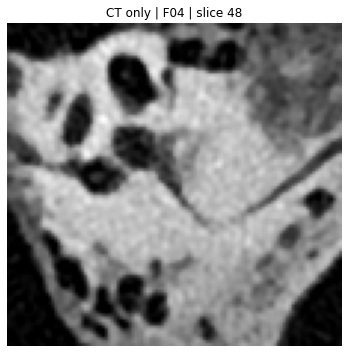

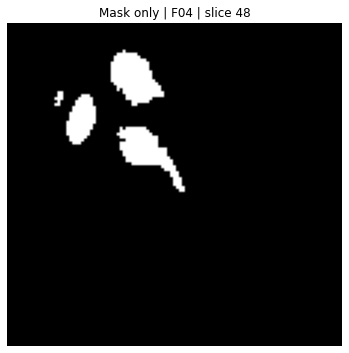

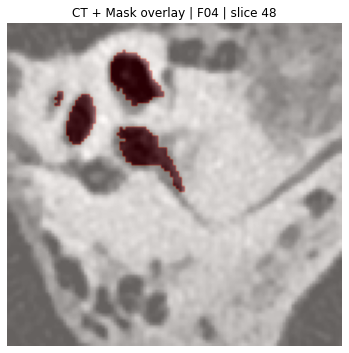

In [39]:
interactive_ct_mask_viewer(train_data)

In [9]:
import numpy as np

print("unique values:", np.unique(mask))
print("mask sum:", np.sum(mask))

unique values: [0. 1.]
mask sum: 803167.0


In [10]:
import torch
from torch.utils.data import Dataset
import nibabel as nib
import numpy as np
import torch.nn.functional as F

class CTDataset2D(Dataset):
    def __init__(self, data_list, size=(128, 128), min_mask_sum=50):
        self.size = size
        self.samples = []

        for item in data_list:
            ct = nib.load(item["ct"]).get_fdata()
            mask = nib.load(item["mask"]).get_fdata()

            depth = ct.shape[2]

            for i in range(depth):

                m = mask[:, :, i]

                # FILTER: skip empty slices
                if m.sum() < min_mask_sum:
                    continue

                self.samples.append((item, i))

    def __len__(self):
        return len(self.samples)

    def normalize(self, img):
        img = img.astype(np.float32)
        return (img - img.mean()) / (img.std() + 1e-8)

    def resize(self, img, is_mask=False):
        img = torch.tensor(img, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

        mode = "nearest" if is_mask else "bilinear"

        img = F.interpolate(
            img,
            size=self.size,
            mode=mode,
            align_corners=False if not is_mask else None
        )

        return img.squeeze(0).squeeze(0)

    def __getitem__(self, idx):
        item, i = self.samples[idx]

        ct = nib.load(item["ct"]).get_fdata()
        mask = nib.load(item["mask"]).get_fdata()

        depth = ct.shape[2]

        # 3 adjacent slices
        i0 = max(i - 1, 0)
        i1 = i
        i2 = min(i + 1, depth - 1)

        s0 = self.resize(self.normalize(ct[:, :, i0]), is_mask=False)
        s1 = self.resize(self.normalize(ct[:, :, i1]), is_mask=False)
        s2 = self.resize(self.normalize(ct[:, :, i2]), is_mask=False)

        # STACK → (3, H, W)
        ct_tensor = torch.stack([s0, s1, s2], dim=0)

        mask_slice = self.resize(mask[:, :, i], is_mask=True)
        mask_tensor = (mask_slice > 0.5).float().unsqueeze(0)

        return ct_tensor, mask_tensor

In [11]:
import SimpleITK as sitk
import os

def preprocess_subject(ct_path, mask_path, out_mask_path):
    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(ct)
    resampler.SetInterpolator(sitk.sitkNearestNeighbor)

    mask_aligned = resampler.Execute(mask)

    sitk.WriteImage(mask_aligned, out_mask_path)


for item in train_data + val_data + test_data:
    ct_path = item["ct"]
    mask_path = item["mask"]

    out_mask = mask_path.replace(".nii", "_aligned.nii")

    preprocess_subject(ct_path, mask_path, out_mask)

    item["mask"] = out_mask

In [12]:
from torch.utils.data import DataLoader

train_dataset = CTDataset2D(train_data)
val_dataset = CTDataset2D(val_data)
test_dataset = CTDataset2D(test_data)


train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)


print("Train samples:", len(train_dataset))

Train samples: 1108


In [13]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNetSmall(nn.Module):
    def __init__(self):
        super().__init__()
        self.down1 = DoubleConv(3, 32)   # 3 input channels if you use 3 slices
        self.pool = nn.MaxPool2d(2)
        self.down2 = DoubleConv(32, 64)
        self.down3 = DoubleConv(64, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv1 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv2 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        x1 = self.down1(x)
        x2 = self.pool(x1)
        x3 = self.down2(x2)
        x4 = self.pool(x3)
        x5 = self.down3(x4)

        x = self.up1(x5)
        x = torch.cat([x, x3], dim=1)
        x = self.conv1(x)

        x = self.up2(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv2(x)

        return self.out(x)  # no sigmoid here

In [14]:
import torch
import torch.nn as nn


class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, target, eps=1e-6):

        probs = torch.sigmoid(logits)

        bce = self.bce(logits, target)

        intersection = (probs * target).sum(dim=(1,2,3))
        union = probs.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

        dice = (2 * intersection + eps) / (union + eps)

        dice_loss = 1 - dice.mean()

        return bce + dice_loss

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = UNetSmall().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = DiceBCELoss()

for epoch in range(25):

    model.train()
    total_loss = 0

    for ct, mask in train_loader:

        ct = ct.to(device)
        mask = mask.to(device)

        logits = model(ct)
        loss = criterion(logits, mask)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch}: Loss = {total_loss/len(train_loader):.4f}")

Epoch 0: Loss = 1.2550
Epoch 1: Loss = 0.8701
Epoch 2: Loss = 0.6172
Epoch 3: Loss = 0.5744
Epoch 4: Loss = 0.5406
Epoch 5: Loss = 0.5048
Epoch 6: Loss = 0.4931
Epoch 7: Loss = 0.4638
Epoch 8: Loss = 0.4318
Epoch 9: Loss = 0.4068
Epoch 10: Loss = 0.3888
Epoch 11: Loss = 0.3749
Epoch 12: Loss = 0.3609
Epoch 13: Loss = 0.3396
Epoch 14: Loss = 0.3236
Epoch 15: Loss = 0.3123
Epoch 16: Loss = 0.2918
Epoch 17: Loss = 0.2728
Epoch 18: Loss = 0.2610
Epoch 19: Loss = 0.2520
Epoch 20: Loss = 0.2391
Epoch 21: Loss = 0.2242
Epoch 22: Loss = 0.2199
Epoch 23: Loss = 0.2042
Epoch 24: Loss = 0.1897


In [19]:
def dice(pred, target, eps=1e-6):
    pred = (pred > 0.5).float()
    target = target.float()

    intersection = (pred * target).sum()
    return (2. * intersection + eps) / (pred.sum() + target.sum() + eps)

In [20]:
model.eval()
scores = []

with torch.no_grad():
    for ct, mask in val_loader:
        ct = ct.to(device)
        mask = mask.to(device)

        pred = model(ct)

        scores.append(dice(pred, mask).item())

print("Dice score:", sum(scores)/len(scores))

Dice score: 0.7747709545595892


In [21]:
torch.save(model.state_dict(), "unet_final.pth")

In [ ]:
# device = "cuda" if torch.cuda.is_available() else "cpu"

# model = UNetSmall().to(device)
# model.load_state_dict(torch.load("unet_final.pth", map_location=device))
# model.eval()

In [22]:
model.eval()
test_scores = []

with torch.no_grad():
    for ct, mask in test_loader:
        ct = ct.to(device)
        mask = mask.to(device)

        logits = model(ct)
        probs = torch.sigmoid(logits)

        test_scores.append(dice(probs, mask).item())

print("Test Dice:", sum(test_scores) / len(test_scores))

Test Dice: 0.7563155929247538


In [23]:
with torch.no_grad():
    logits = model(ct)
    probs = torch.sigmoid(logits)

pred = (probs > 0.5).cpu().numpy()

# CLEAN STEP
import scipy.ndimage as nd

labeled, num = nd.label(pred)
clean = np.zeros_like(pred)

for i in range(1, num+1):
    component = (labeled == i)
    if component.sum() > 50:
        clean[component] = 1

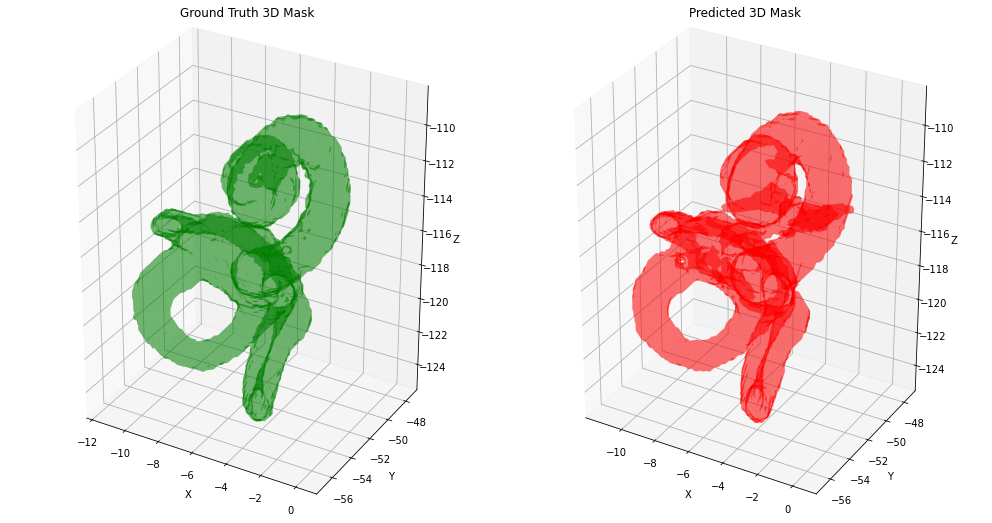

In [49]:
# #3d Visualization

# import os
# import numpy as np
# import nibabel as nib
# import matplotlib.pyplot as plt
# import torch
# import torch.nn.functional as F
# import scipy.ndimage as nd
# from nibabel.affines import apply_affine
# from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# try:
#     from skimage.measure import marching_cubes
# except:
#     from skimage.measure import marching_cubes_lewiner as marching_cubes


# # ============================================================
# # HELPERS
# # ============================================================
# def keep_largest_component(mask):
#     mask_bin = (mask > 0).astype(np.uint8)
#     labeled, num = nd.label(mask_bin)

#     if num == 0:
#         return mask_bin

#     sizes = nd.sum(mask_bin, labeled, range(1, num + 1))
#     largest_label = 1 + int(np.argmax(sizes))
#     return (labeled == largest_label).astype(np.uint8)


# def _add_mask_surface(ax, mask, affine, color="red", alpha=0.35, title="3D Mask"):
#     mask = keep_largest_component(mask)

#     if mask.sum() == 0:
#         ax.set_title(title + " (empty)")
#         ax.axis("off")
#         return

#     mask = np.ascontiguousarray(mask.astype(np.float32))

#     verts, faces, normals, values = marching_cubes(mask, level=0.5)

#     if affine is not None:
#         verts = apply_affine(affine, verts)

#     mesh = Poly3DCollection(verts[faces], alpha=alpha)
#     mesh.set_facecolor(color)
#     mesh.set_edgecolor("none")
#     ax.add_collection3d(mesh)

#     ax.set_title(title)
#     ax.set_xlabel("X")
#     ax.set_ylabel("Y")
#     ax.set_zlabel("Z")

#     ax.set_xlim(verts[:, 0].min(), verts[:, 0].max())
#     ax.set_ylim(verts[:, 1].min(), verts[:, 1].max())
#     ax.set_zlim(verts[:, 2].min(), verts[:, 2].max())

#     ax.set_box_aspect([
#         verts[:, 0].ptp() + 1e-8,
#         verts[:, 1].ptp() + 1e-8,
#         verts[:, 2].ptp() + 1e-8,
#     ])


# # ============================================================
# # PREDICTION
# # ============================================================
# def predict_subject_mask(model, ct_path, device, input_size=(128, 128)):
#     ct_img = nib.load(ct_path)
#     ct = ct_img.get_fdata()
#     X, Y, Z = ct.shape

#     pred_vol = np.zeros((X, Y, Z), dtype=np.uint8)

#     model.eval()
#     with torch.no_grad():
#         for i in range(Z):
#             i0 = max(i - 1, 0)
#             i1 = i
#             i2 = min(i + 1, Z - 1)

#             slices = []
#             for j in [i0, i1, i2]:
#                 s = ct[:, :, j].astype(np.float32)
#                 s = (s - s.mean()) / (s.std() + 1e-8)

#                 t = torch.tensor(s, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
#                 t = F.interpolate(t, size=input_size, mode="bilinear", align_corners=False)
#                 slices.append(t.squeeze(0).squeeze(0))

#             x = torch.stack(slices, dim=0).unsqueeze(0).to(device)  # (1, 3, H, W)

#             logits = model(x)
#             probs = torch.sigmoid(logits)
#             pred = (probs > 0.5).float()

#             pred_2d = F.interpolate(
#                 pred,
#                 size=(X, Y),
#                 mode="nearest"
#             ).squeeze().cpu().numpy().astype(np.uint8)

#             pred_vol[:, :, i] = pred_2d

#     pred_vol = keep_largest_component(pred_vol)
#     return pred_vol


# # ============================================================
# # 3D VISUALIZATION
# # ============================================================
# def visualize_3d_masks(ct_path, model, device, gt_mask_path=None):
#     ct_img = nib.load(ct_path)
#     affine = ct_img.affine

#     pred_mask = predict_subject_mask(model, ct_path, device)

#     fig = plt.figure(figsize=(14, 7))

#     # Ground truth
#     ax1 = fig.add_subplot(1, 2, 1, projection="3d")
#     if gt_mask_path is not None:
#         gt = nib.load(gt_mask_path).get_fdata()
#         gt = (gt > 0).astype(np.uint8)
#         if gt.shape != ct_img.shape:
#             raise ValueError(
#                 f"GT shape {gt.shape} does not match CT shape {ct_img.shape}. "
#                 f"Check alignment / resampling."
#             )
#         _add_mask_surface(ax1, gt, affine, color="green", alpha=0.35, title="Ground Truth 3D Mask")
#     else:
#         ax1.text(0.5, 0.5, 0.5, "No GT mask", ha="center")
#         ax1.axis("off")

#     # Prediction
#     ax2 = fig.add_subplot(1, 2, 2, projection="3d")
#     if pred_mask is not None:
#         if pred_mask.shape != ct_img.shape:
#             raise ValueError(
#                 f"Predicted mask shape {pred_mask.shape} does not match CT shape {ct_img.shape}. "
#                 f"Prediction pipeline is producing a mismatched volume."
#             )
#         _add_mask_surface(ax2, pred_mask, affine, color="red", alpha=0.35, title="Predicted 3D Mask")
#     else:
#         ax2.text(0.5, 0.5, 0.5, "No prediction", ha="center")
#         ax2.axis("off")

#     plt.tight_layout()
#     plt.show()


# # ============================================================
# # RUN IT ON ONE SAMPLE
# # ============================================================
# sample = test_data[0]
# ct_path = sample["ct"]
# gt_mask_path = sample["mask"]

# visualize_3d_masks(ct_path, model, device, gt_mask_path=gt_mask_path)